# Final Analysis: Regression With Conformal Prediction

Primary final analysis notebook using the processed rental features.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

## Load Processed Dataset

In [2]:
df = pd.read_csv("full_rent_features.csv")
df["log_median_rent_psq"] = np.log(df["median_rent_psq"])

df.head()

,lat,lon,median_rent,median_rent_psq,listing_count,shores_beach_ft,utc_ft,downtown_ft,nearest_school_ft,nearest_park_ft,nearest_bus_stop_ft,log_median_rent_psq
0,32.850104,-117.206734,2947.5,2.841849,32,15680.840376,7689.998749,49506.386061,1011.028127,788.006465,1011.028127,1.044455
1,32.863718,-117.223166,2356.0,3.487730,50,10575.018050,4604.560916,55725.081733,939.894454,1240.946569,939.894454,1.249251
2,32.861147,-117.200341,2995.0,3.531840,50,17415.346976,4811.947426,52950.806747,1251.092039,1556.491731,1251.092039,1.261819
3,32.861097,-117.206854,2945.0,3.606719,50,15418.940484,3790.271635,53385.329164,761.561734,1121.451834,761.561734,1.282799
4,32.852801,-117.213276,4600.0,2.500000,25,13538.903683,6644.916957,51008.484323,1158.761962,1500.046061,1158.761962,0.916291


## Candidate Model Formulas

In [3]:
from itertools import combinations

feature_cols = df.drop(
    columns=["lat", "lon", "median_rent", "median_rent_psq", "listing_count", "log_median_rent_psq"]
).columns

formulas = []
log_formulas = []

for i in range(len(feature_cols) + 1):
    for subset in combinations(feature_cols, i):
        if len(subset) == 0:
            formulas.append("median_rent_psq ~ 1")
            log_formulas.append("log_median_rent_psq ~ 1")
        else:
            formulas.append(f"median_rent_psq ~ {' + '.join(subset)}")
            log_formulas.append(f"log_median_rent_psq ~ {' + '.join(subset)}")

## Train/Calibration Split and AIC Selection

In [4]:
from sklearn.model_selection import train_test_split

train_df, cal_df = train_test_split(df, test_size=0.25, random_state=1)

models = []
log_models = []

for formula in formulas:
    models.append(smf.ols(formula=formula, data=train_df).fit().aic)

for formula in log_formulas:
    log_models.append(smf.ols(formula=formula, data=train_df).fit().aic)

print(f"Best regular model is {formulas[np.argmin(models)]} with AIC: {np.min(models)}")
print(f"Best regular model is {log_formulas[np.argmin(log_models)]} with AIC: {np.min(log_models)}")

Best regular model is median_rent_psq ~ shores_beach_ft + utc_ft with AIC: 123.99743085539987
Best regular model is log_median_rent_psq ~ shores_beach_ft + utc_ft with AIC: -124.39912816051637


## BIC Model Selection

In [5]:
models = []
log_models = []

for formula in formulas:
    models.append(smf.ols(formula=formula, data=train_df).fit().bic)

for formula in log_formulas:
    log_models.append(smf.ols(formula=formula, data=train_df).fit().bic)

print(f"Best regular model is {formulas[np.argmin(models)]} with BIC: {np.min(models)}")
print(f"Best regular model is {log_formulas[np.argmin(log_models)]} with BIC: {np.min(log_models)}")

Best regular model is median_rent_psq ~ shores_beach_ft + utc_ft with BIC: 131.78279040580364
Best regular model is log_median_rent_psq ~ shores_beach_ft + utc_ft with BIC: -116.6137686101126


## Final Regression Model

In [6]:
model = smf.ols(
    formula="log_median_rent_psq ~ shores_beach_ft + utc_ft", data=train_df
).fit()

## Conformal Prediction Interval

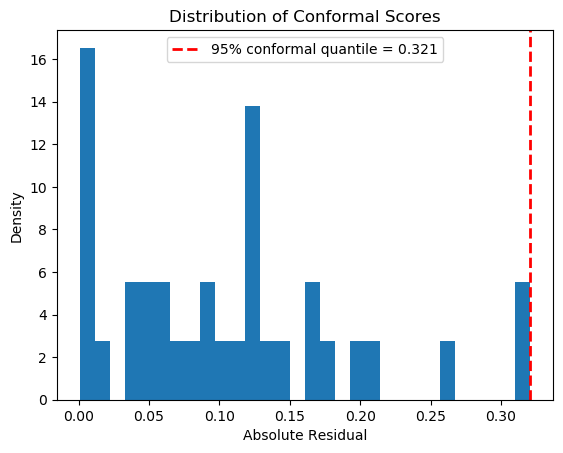

In [7]:
m = len(cal_df)

y = model.predict(cal_df)

conf_score = np.abs(y - cal_df["log_median_rent_psq"])

alpha = 0.05
q = np.quantile(conf_score, np.ceil((m + 1) * (1 - alpha) / m), method="higher")

pred_lower = y - q
pred_upper = y + q

plt.hist(conf_score, bins=30, density=True)

plt.axvline(
    q,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"{int(100*(1-alpha))}% conformal quantile = {q:.3f}"
)

plt.xlabel("Scores")
plt.ylabel("Count")
plt.title("Distribution of Conformal Scores")
plt.legend()
plt.show()

## UCSD On-Campus Housing Comparison

In [8]:
data_ucsd = {"log_median_rent_psq": np.log(7.51), "shores_beach_ft": 12038, "utc_ft": 10616}

df_test = pd.DataFrame([data_ucsd])

y = model.predict(df_test)

pred = y.item()

log_price = data_ucsd["log_median_rent_psq"]

print(f"Model predicted: {pred}\n      vs      \nActual pricing:  {log_price}")

lower = pred - q
upper = pred + q

print(f"Confidence interval ({lower}, {upper}) for alpha = {alpha}")

Model predicted: 1.1146235511118412
      vs      
Actual pricing:  2.0162354657760435
Confidence interval (0.7937383740196592, 1.4355087282040233) for alpha = 0.05


## Multicollinearity Check

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_calculator(model):
    X = model.model.exog
    names = model.model.exog_names

    vif = pd.DataFrame({
        "Variable": names,
        "VIF": [variance_inflation_factor(X, i)
                for i in range(X.shape[1])]
    })

    return vif

print(vif_calculator(model))

          Variable        VIF
0        Intercept  21.604701
1  shores_beach_ft   1.291866
2           utc_ft   1.291866


## Regression Diagnostics

Text(0, 0.5, 'Residuals')

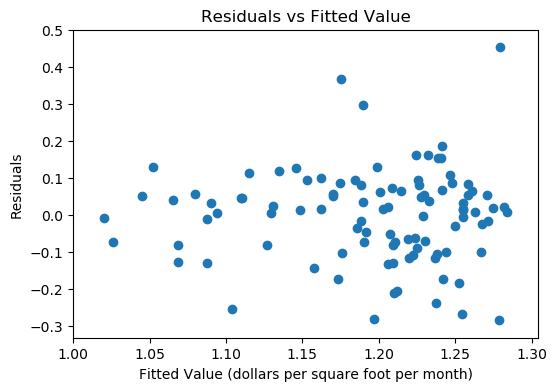

In [10]:
import matplotlib.pyplot as plt

fitted = model.fittedvalues
residuals = model.resid

plt.figure(figsize=(6, 4))
plt.scatter(fitted, residuals)
plt.title("Residuals vs Fitted Value")
plt.xlabel("Fitted Value (dollars per square foot per month)")
plt.ylabel("Residuals")

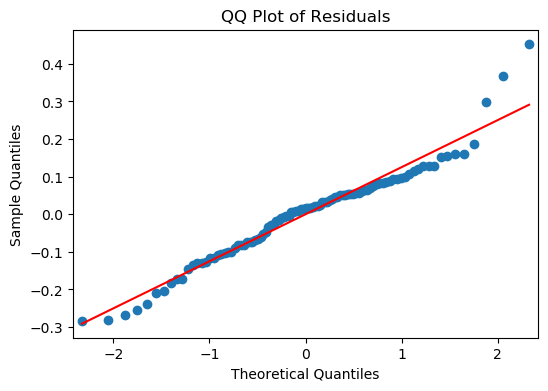

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sm.qqplot(model.resid, line="s", ax=ax)
plt.title("QQ Plot of Residuals");

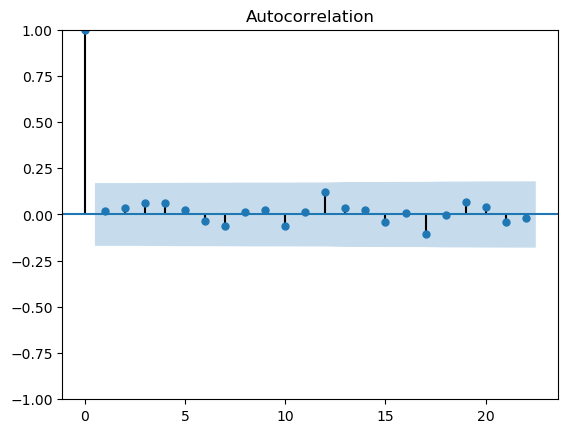

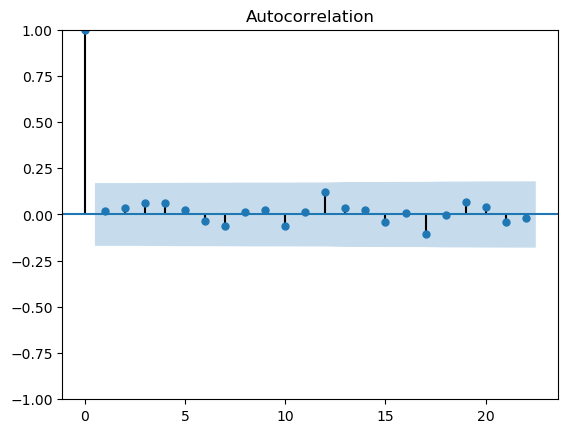

In [12]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(df["log_median_rent_psq"])

## Rent Per Square Foot Distribution

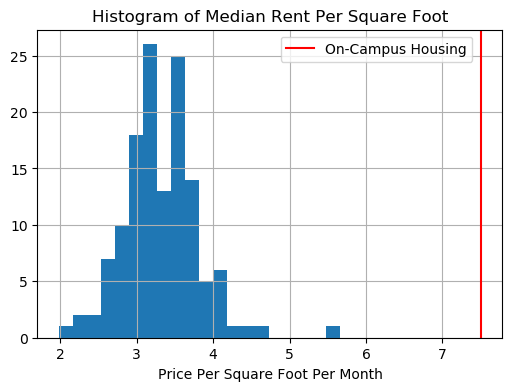

In [13]:
fig, ax = plt.subplots(figsize=(6,4))
df["median_rent_psq"].hist(ax=ax, bins=20)
plt.axvline(x=7.51, color="red", label="On-Campus Housing")
plt.title("Histogram of Median Rent Per Square Foot")
plt.xlabel("Price Per Square Foot Per Month")
plt.legend(loc="upper right", bbox_to_anchor=(0.95, 1));

## Statsmodels Prediction Interval

In [14]:
pred_df = pd.DataFrame({
    "shores_beach_ft": [12038],
    "utc_ft": [10616],
    "nearest_park_ft": [436] 
})

pred = model.get_prediction(pred_df)
summary = pred.summary_frame(alpha=0.01)
print(summary)

       mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0  1.114624  0.022936       1.054347         1.1749      0.774995   

   obs_ci_upper  
0      1.454252  
